In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

 # **`Task 1: Exploratory Data Analysis(EDA)`**

**1.	Load the dataset and perform fundamental data exploration.**

In [2]:
#load the dataset
df = pd.read_csv('Pharma_Industry.csv')

In [3]:
df.shape

(500, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [5]:
df.head()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


EDA

In [6]:
#missing values
df.isnull().sum()

,0
Drug Dosage (mg),0
Systolic Blood Pressure (mmHg),0
Heart Rate (BPM),0
Liver Toxicity Index (U/L),0
Blood Glucose Level (mg/dL),0
Drug Response,0


In [7]:
#duplicates
df.duplicated().sum()

np.int64(0)

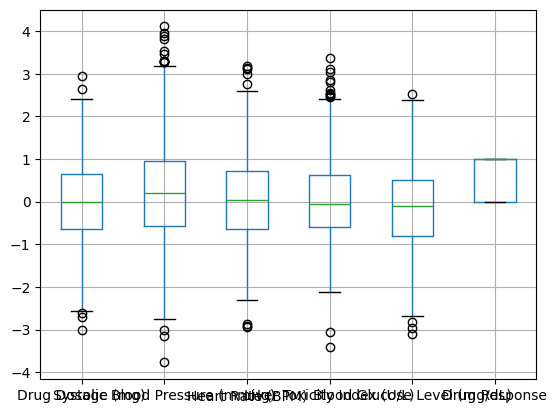

In [8]:
#checking outliers
df.boxplot()
plt.show()

In [9]:
#outlier capping
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int64', 'float64']).columns:
  outlier_capping(df, col)

**2.	Utilize histograms, box plots, or density plots to understand feature distributions.**

HISTOGRAM

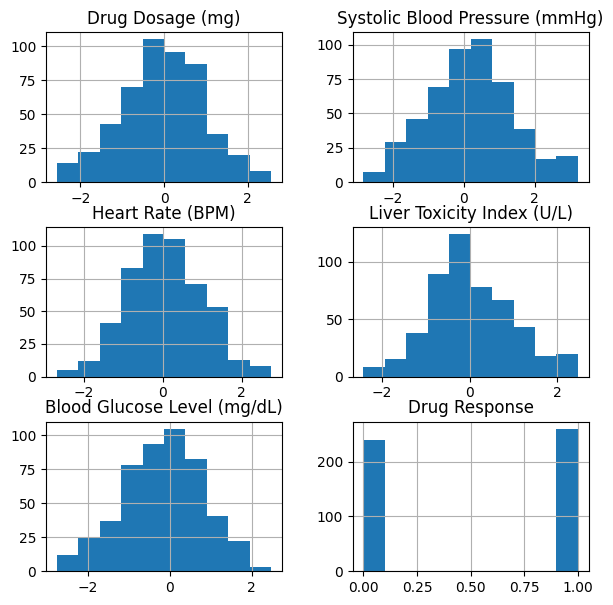

In [10]:
df.hist(figsize=(7,7))
plt.show()

BOXPLOT

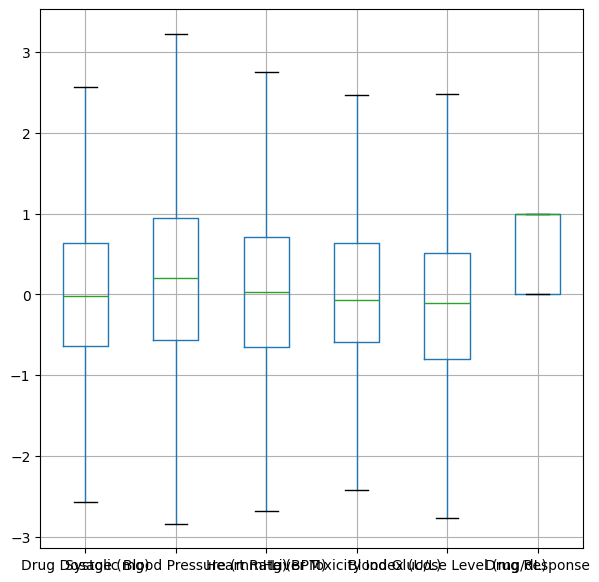

In [11]:
df.boxplot(figsize=(7,7))
plt.show()

DENSITY PLOT

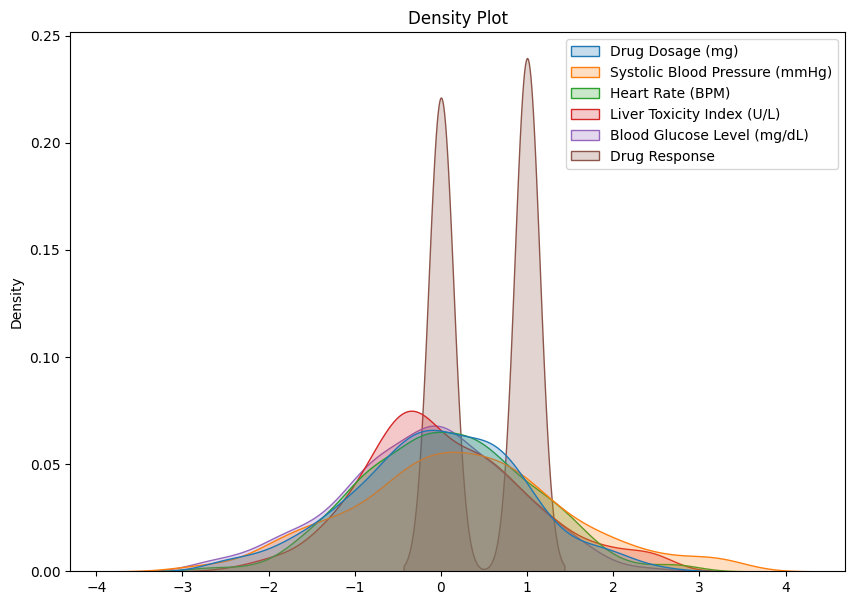

In [12]:
plt.figure(figsize=(10,7))
sns.kdeplot(data=df, fill=True)
plt.title('Density Plot')
plt.show()

**3.	Investigate feature correlations to discuss relationships within the data.**

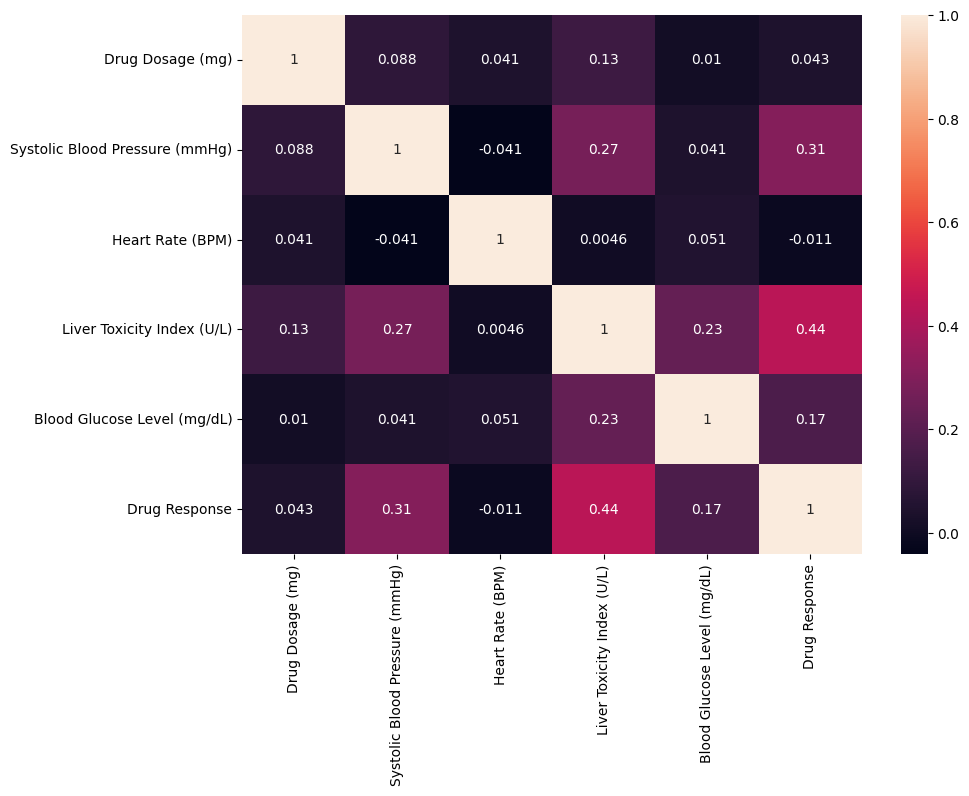

In [13]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(), annot=True)
plt.show()

A correlation matrix was used to analyse relationships between numerical features. This helps identify features that are strongly related and may influence that model's performance

**Explanation:**
---

First, the dataset was loaded and basic exploration was done to understand the data. Then, visualizations like histograms, box plots, and density plots were used to study the distribution of numerical features. Box plots helped in identifying outliers, while density plots showed the spread and skewness of the data. Finally, correlation analysis was performed to understand relationships between different features within the data.

# **`Task 2: Data Preprocessing`**

**1.	Encode categorical variables if necessary.**

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


The dataset does not contain any categorical columns.

**2.	Split the dataset into training and testing sets.**

In [15]:
target = df[['Drug Response']]
features = df.drop(columns = ['Drug Response'])

In [16]:
#spliting training and testing dataset
x_train, x_test, y_train, y_test = train_test_split(features,target, train_size = 0.8, random_state = 50)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 5)
(100, 5)
(400, 1)
(100, 1)


**Explanation**
---

The dataset was checked to identify categorical columns. Since all features are numerical and the target is already encoded, no categorical encoding was required. Next, the dataset was split into training and testing sets to evaluate the model’s performance on unseen data.

# **`Task 3: Data Visualization`**

**1.	Employ scatter plots, pair plots, or relevant visualizations to comprehend feature distributions and relationships.**

SCATTER PLOT

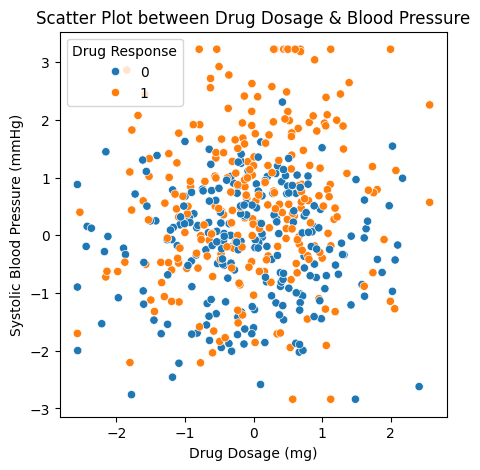

In [17]:
plt.figure(figsize =(5,5))
sns.scatterplot(data = df, x = df['Drug Dosage (mg)'], y = df['Systolic Blood Pressure (mmHg)'], hue = df['Drug Response'])
plt.title('Scatter Plot between Drug Dosage & Blood Pressure')
plt.show()

PAIRPLOT

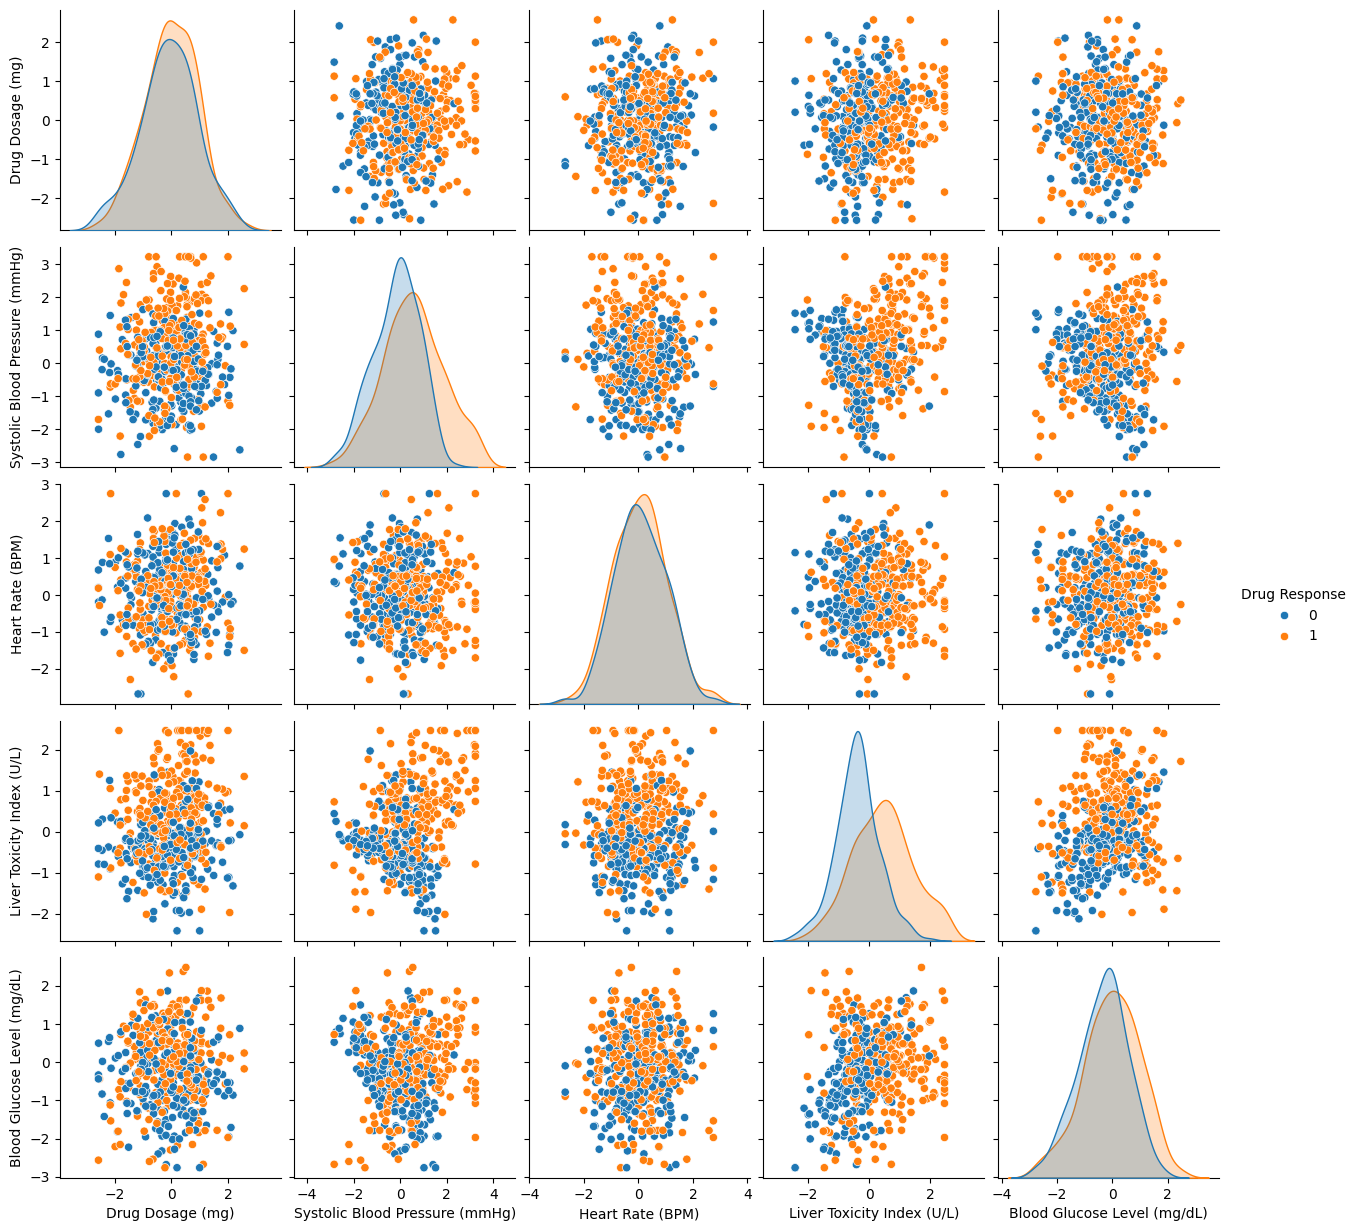

In [18]:
sns.pairplot(df, hue = 'Drug Response', diag_kind='kde')
plt.show()

**2.	Visualize class distributions to gauge dataset balance or imbalance.**

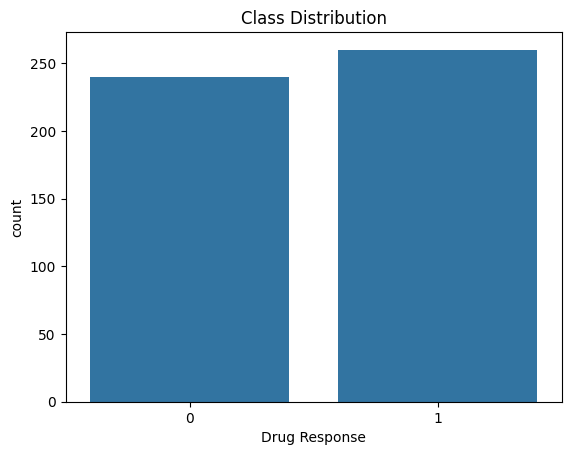

In [19]:
sns.countplot(data = df, x = 'Drug Response')
plt.title('Class Distribution')
plt.show()

**Explanation:**
---

In this task, scatter plot was created to observe the relationship between drug dosage and systolic blood pressure, with colors representing different drug response classes.
A pair plot was also used to visualize relationships among all numerical features and to observe how the classes are distributed across feature combinations.
Finally, a count plot was used to visualize the class distribution.

# **`Task 4: SVM Implementation`**

**1.	Implement a basic SVM classifier using Python libraries like scikit-learn.**

In [20]:
#basic SVM classifier with linear kernel
svc = SVC(C=1,kernel='linear')

**2.	Train the SVM model on the training data.**

In [21]:
svc.fit(x_train, y_train)

SVC(C=1, kernel='linear')

**3.	Evaluate model performance on the testing data using appropriate metrics (e.g., accuracy, precision, recall, F1-score).**

In [22]:
y_pred = svc.predict(x_test)

acc = accuracy_score(y_test, y_pred)
pre = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [23]:
print("Accuarcy:", acc )
print("Precision:" , pre)
print("Recall:", recall)
print("F1-score:", f1)

Accuarcy: 0.77
Precision: 0.8409090909090909
Recall: 0.6981132075471698
F1-score: 0.7628865979381443


**Explanation:**
---

A Support Vector Machine(SVM) classifier was implemented using the scikit-learn library. The model was trained on the training dataset to learn patterns and separate the classes effectively. After training, the model was evaluated on the test dataset using performance metrics such as accuracy, precision, recall, and F1-score. These metrics were used to assess how well the model predicts the drug response and balances correct and incorrect predictions.

# **`Task 5: Visualization of SVM Results`**

**1.	Visualize classification results on the testing data.**

In [24]:
import numpy as np

In [25]:
#taking only first 2 features for visualisation
x_train_2 = x_train.iloc[:, :2]
x_test_2 = x_test.iloc[:, :2]

In [26]:
#training SVM with linear kernel for these 2 features
svc_vis = SVC(C=1,kernel='linear')
svc_vis.fit(x_train_2, y_train)

SVC(C=1, kernel='linear')

In [27]:
#finding minimum and maximum values for selected columns
x1_min = x_train_2['Drug Dosage (mg)'].min()
x1_max = x_train_2['Drug Dosage (mg)'].max()

x2_min = x_train_2['Systolic Blood Pressure (mmHg)'].min()
x2_max = x_train_2['Systolic Blood Pressure (mmHg)'].max()

In [28]:
x1_min, x1_max, x2_min, x2_max

(-2.5667328734783985,
 2.5658810828304035,
 -2.839982200906558,
 3.2261886690991717)

In [29]:
#extending the boundary so that no point lies on the border
x_min, x_max, y_min, y_max = x1_min-1, x1_max+1, x2_min-1, x2_max+1

In [30]:
#lets take step size as 0.1
h = 0.1

In [31]:
#creating meshgrid
xx = np.arange(x_min, x_max, h)
yy = np.arange(y_min, y_max, h)

xx, yy = np.meshgrid(xx, yy)

In [32]:
type(np.meshgrid(xx,yy))

tuple

In [33]:
xx.ndim

2

In [34]:
yy.ndim

2

In [35]:
#to convert 2D to 1D while predicting
data = np.c_[np.ravel(xx), np.ravel(yy)]


In [36]:
data.shape

(5832, 2)

In [37]:
z = svc_vis.predict(data)
z

array([0, 0, 0, ..., 1, 1, 1])

In [38]:
xx.shape, yy.shape, z.shape

((81, 72), (81, 72), (5832,))

In [39]:
#shape is mismatching, so we will reshape
xx.ndim, yy.ndim, z.ndim

(2, 2, 1)

In [40]:
#reshaping z to 2D, so we can plot
z1 = z.reshape(xx.shape)
z1.shape

(81, 72)

In [41]:
z1.ndim

2

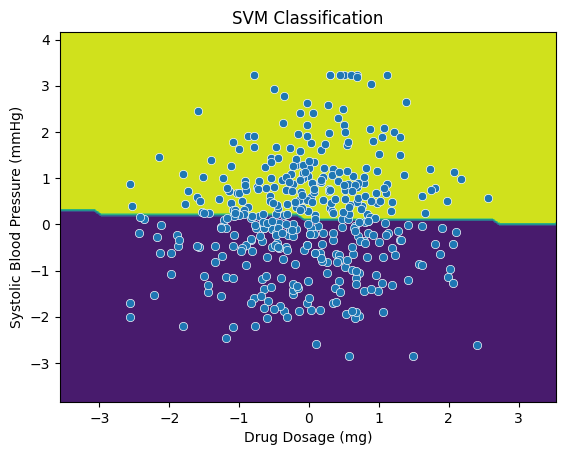

In [42]:
#2D plotting
plt.contourf(xx, yy, z1)
sns.scatterplot(data=df, x=x_train_2['Drug Dosage (mg)'], y=x_train_2['Systolic Blood Pressure (mmHg)'])

plt.xlabel('Drug Dosage (mg)')
plt.ylabel('Systolic Blood Pressure (mmHg)')
plt.title('SVM Classification')
plt.show()

**Explanation:**
---

A contour plot was used to visualize the decision regions based on Drug Dosage and Systolic Blood Pressure. The background colors represent different predicted classes, while the scatter plot shows the actual testing data points.

# **`Task 6: Parameter Tuning and Optimization`**



**1.	Experiment with different SVM hyperparameters (e.g., kernel type, regularization parameter) to optimize performance.**

Different type of kernels

In [43]:
#linear kernel
svc_linear =  SVC(kernel = 'linear', C=1)
svc_linear.fit(x_train, y_train)

SVC(C=1, kernel='linear')

In [44]:
y_pred_linear = svc_linear.predict(x_test)
acc_linear = accuracy_score(y_test, y_pred_linear)

acc_linear

0.77

In [45]:
#poly kernel
svc_poly = SVC(kernel = 'poly', C=1)
svc_poly.fit(x_train, y_train)

SVC(C=1, kernel='poly')

In [46]:
y_pred_poly = svc_poly.predict(x_test)
acc_poly = accuracy_score(y_test, y_pred_poly)

acc_poly

0.75

In [47]:
#radial basis
svc_rbf = SVC(kernel='rbf', C=1)
svc_rbf.fit(x_train, y_train)

SVC(C=1)

In [48]:
y_pred_rbf = svc_rbf.predict(x_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)

acc_rbf

0.8

In [49]:
#sigmoid kernel
svc_sig = SVC(kernel='sigmoid', C=1)
svc_sig.fit(x_train, y_train)

SVC(C=1, kernel='sigmoid')

In [51]:
y_pred_sig = svc_sig.predict(x_test)
acc_sig = accuracy_score(y_test, y_pred_sig)

acc_sig

0.63

In [52]:
acc_linear, acc_poly, acc_rbf, acc_sig

(0.77, 0.75, 0.8, 0.63)

Different C values

In [55]:
#regularisation coefficient(C)
C_values = [0.01, 0.05, 0.07, 1, 10]

In [56]:
acc_C = []

In [57]:
for c in C_values:
  svc_C = SVC(kernel='linear', C=c)
  svc_C.fit(x_train, y_train)

  y_pred = svc_C.predict(x_test)
  acc = accuracy_score(y_test, y_pred)
  acc_C.append(acc)

C_values, acc_C

([0.01, 0.05, 0.07, 1, 10], [0.75, 0.76, 0.76, 0.77, 0.77])

**Explanation:**
---

In this, SVM performance was improved by experimenting with different kernels and the regularization parameter (C). Among linear, polynomial, RBF, sigmoid kernels, the RBF kernel achieved the highest accuracy, showing it captures non-linear patterns effectively. Tuning the C value helped balance model complexity and generalization. Overall, the RBF kernel with an optimal C(C=1) value gave the best performance on the dataset.



#

# **`Task 7: Comparison and Analysis`**



**1.	Compare SVM performance with various kernels (e.g., linear, polynomial, radial basis function).**




In [58]:
print("Accuracy of Linear kernel:", acc_linear)
print("Accuracy of Poly Kernel:", acc_poly)
print("Accuarcy of RBF kernel:", acc_rbf)

Accuracy of Linear kernel: 0.77
Accuracy of Poly Kernel: 0.75
Accuarcy of RBF kernel: 0.8


SVM model was evaluated using different kernels. Among them, the RBF kernel achieved the highest accuracy, indicating its ability to capture non-linear relationships in the dataset. The linear kernel performed reasonably well, while the polynomial kernel showed comparatively lower performance

**2.	Analyze SVM strengths and weaknesses for the dataset based on EDA and visualization results.**


SVM is effective in high-dimensional spaces and works well with clear margin separation. However, its performance depends heavily on kernel selection and hyperparameter tuning, such as C and kernel parameters. Here RBF kernel gives best accuracy and Regularisation Coefficient C = 1 gives best accuracy.



**3.	Discuss practical implications of SVM in real-world classification tasks.**

SVM classifiers are widely used in real-world classification problems such as medical diagnosis and text classification. Proper kernel and parameter selection is essential to achieve optimal performance.